<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Case_Study_3_Housing_Prices_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSSP607 Case Study Report Assignment 3
## Housing Prices in ABC

**Student:** Kai Xing


## 1. Setup and load data



In [1]:
import os
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Use the GitHub workflow in Google Colab
if "google.colab" in sys.modules:
    owner = "kaixing189"
    repository = "MSSP607"
    repo_url = f"https://github.com/{owner}/{repository}.git"
    repo_path = Path("/content") / repository

    if not repo_path.exists():
        subprocess.run(["git", "clone", repo_url, str(repo_path)], check=True)
    else:
        subprocess.run(["git", "pull"], cwd=repo_path, check=True)

    os.chdir(repo_path)
    print("Current directory:", os.getcwd())

# Find the data file
candidates = [
    Path("data/HousingPrices.csv"),
    Path("HousingPrices.csv"),
    Path("/content/HousingPrices.csv"),
    Path("/mnt/data/HousingPrices.csv"),
]

data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("HousingPrices.csv was not found. Add it to MSSP607/data or upload it to Colab.")

df = pd.read_csv(data_path)
print("Data path:", data_path)
print("Shape:", df.shape)
display(df.head())

Current directory: /content/MSSP607
Data path: data/HousingPrices.csv
Shape: (1460, 17)


,Id,LotFrontage,LotArea,HouseStyle,OverallQual,OverallCond,YearBuilt,TotalBsmtSF,CentralAir,1stFlrSF,2ndFlrSF,FullBath,TotalRooms,GarageCars,GarageArea,YrSold,SalePrice
0,1,65.00,"8,450.00",2Story,7,5,2003,856.00,Y,856,854,2,8,2,548,2008,208500
1,2,80.00,"9,600.00",1Story,6,8,1976,NaN,Y,1262,0,2,6,2,460,2007,181500
2,3,68.00,"11,250.00",2Story,7,5,2001,920.00,Y,920,866,2,6,2,608,2008,223500
3,4,60.00,"9,550.00",2Story,7,5,1915,NaN,Y,961,756,1,7,3,642,2006,140000
4,5,84.00,"14,260.00",2Story,8,5,2000,"1,145.00",Y,1145,1053,2,9,3,836,2008,250000


## 2. Data quality and descriptive overview

In [2]:
print("Columns:")
print(df.columns.tolist())

missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Percent": df.isna().mean() * 100
}).sort_values("Missing", ascending=False)

display(missing[missing["Missing"] > 0].round(2))

df["TotalLivingSF"] = df["1stFlrSF"] + df["2ndFlrSF"]
df["AgeAtSale"] = df["YrSold"] - df["YearBuilt"]

Columns:
['Id', 'LotFrontage', 'LotArea', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'TotalBsmtSF', 'CentralAir', '1stFlrSF', '2ndFlrSF', 'FullBath', 'TotalRooms', 'GarageCars', 'GarageArea', 'YrSold', 'SalePrice']


,Missing,Percent
TotalBsmtSF,547,37.47
LotFrontage,259,17.74
LotArea,119,8.15


Three variables have missing values: `TotalBsmtSF`, `LotFrontage`, and `LotArea`. The required sale-price analysis does not depend on these fields, so no homes need to be dropped for Questions 1–3. Analyses using variables with missing values use pairwise available observations.

## 3. Question 1: Mean and standard deviation of housing price

In [3]:
price_summary = df["SalePrice"].agg(["count", "mean", "std", "median", "min", "max"])
print(price_summary)

print(f"Mean sale price: ${df['SalePrice'].mean():,.2f}")
print(f"Standard deviation: ${df['SalePrice'].std(ddof=1):,.2f}")
print(f"Median sale price: ${df['SalePrice'].median():,.2f}")

count      1,460.00
mean     180,921.20
std       79,442.50
median   163,000.00
min       34,900.00
max      755,000.00
Name: SalePrice, dtype: float64
Mean sale price: $180,921.20
Standard deviation: $79,442.50
Median sale price: $163,000.00


**Answer:** The mean sale price is **$180,921.20** and the sample standard deviation is **$79,442.50**. The median is **$163,000**, which is below the mean and suggests that higher-priced homes pull the average upward.

## 4. Question 2: Histogram of housing price

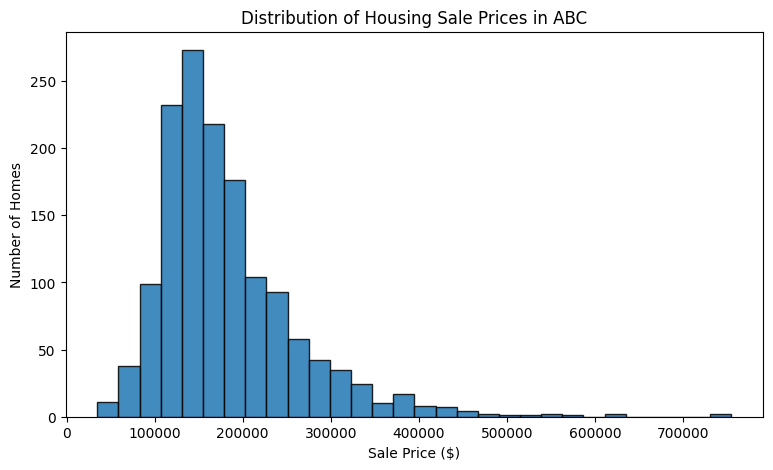

Sale-price skewness: 1.883


In [4]:
plt.figure(figsize=(9, 5))
plt.hist(df["SalePrice"], bins=30, edgecolor="black", alpha=0.85)
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Homes")
plt.title("Distribution of Housing Sale Prices in ABC")
plt.show()

print(f"Sale-price skewness: {df['SalePrice'].skew():.3f}")

**Interpretation:** The distribution is **right-skewed** (skewness = **1.88**). Most homes sell in the lower and middle portions of the range, while a relatively small number of expensive homes create a long upper tail.

## 5. Question 3: Outlier analysis

Q1: $129,975.00
Q3: $214,000.00
IQR: $84,025.00
Lower IQR fence: $3,937.50
Upper IQR fence: $340,037.50
Number of IQR outliers: 61 (4.18%)
Minimum outlier price: $341,000.00
Maximum price: $755,000.00


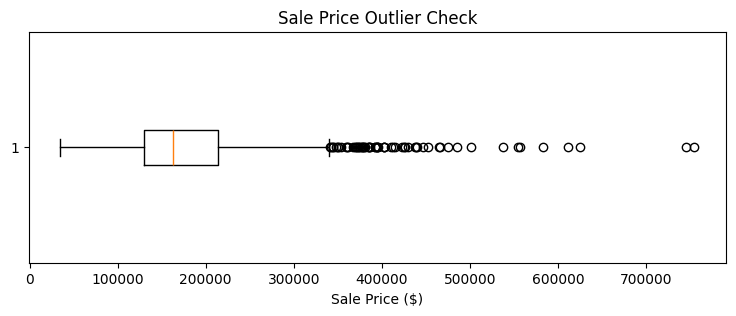

,Id,SalePrice,OverallQual,YearBuilt,GarageCars,1stFlrSF,2ndFlrSF
691,692,755000,10,1994,3,2444,1872
1182,1183,745000,10,1996,3,2411,2065
1169,1170,625000,10,1995,3,1831,1796
898,899,611657,9,2009,3,2364,0
803,804,582933,9,2008,3,1734,1088
1046,1047,556581,9,2005,3,1992,876
440,441,555000,10,2008,3,2402,0
769,770,538000,8,2003,3,1690,1589
178,179,501837,9,2008,3,2234,0
798,799,485000,9,2008,3,1966,1174


In [5]:
q1 = df["SalePrice"].quantile(0.25)
q3 = df["SalePrice"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df["SalePrice"] < lower_bound) | (df["SalePrice"] > upper_bound)].copy()

print(f"Q1: ${q1:,.2f}")
print(f"Q3: ${q3:,.2f}")
print(f"IQR: ${iqr:,.2f}")
print(f"Lower IQR fence: ${lower_bound:,.2f}")
print(f"Upper IQR fence: ${upper_bound:,.2f}")
print(f"Number of IQR outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")
print(f"Minimum outlier price: ${outliers['SalePrice'].min():,.2f}")
print(f"Maximum price: ${df['SalePrice'].max():,.2f}")

plt.figure(figsize=(9, 3))
plt.boxplot(df["SalePrice"], vert=False)
plt.xlabel("Sale Price ($)")
plt.title("Sale Price Outlier Check")
plt.show()

display(outliers.sort_values("SalePrice", ascending=False)[
    ["Id", "SalePrice", "OverallQual", "YearBuilt", "GarageCars", "1stFlrSF", "2ndFlrSF"]
].head(10))

In [6]:
non_outliers = df[df["SalePrice"] <= upper_bound]

sensitivity = pd.DataFrame({
    "Measure": ["All homes", "Excluding IQR high-price outliers"],
    "N": [len(df), len(non_outliers)],
    "Mean": [df["SalePrice"].mean(), non_outliers["SalePrice"].mean()],
    "SD": [df["SalePrice"].std(ddof=1), non_outliers["SalePrice"].std(ddof=1)],
    "Median": [df["SalePrice"].median(), non_outliers["SalePrice"].median()]
})
display(sensitivity.round(2))

print("Skewness of SalePrice:", round(df["SalePrice"].skew(), 3))
print("Skewness of log(SalePrice):", round(np.log(df["SalePrice"]).skew(), 3))

,Measure,N,Mean,SD,Median
0,All homes,1460,"180,921.20","79,442.50","163,000.00"
1,Excluding IQR high-price outliers,1399,"170,237.13","59,230.13","159,500.00"


Skewness of SalePrice: 1.883
Skewness of log(SalePrice): 0.121


**Answer:** The 1.5×IQR rule identifies **61 homes (4.2%)** above approximately **$340,038** as high-price outliers. There are no low-price IQR outliers. These observations should **not be automatically deleted** because they appear to represent a premium segment of the market rather than obvious data-entry errors. For descriptive reporting, I would keep them, report the median in addition to the mean, and use a sensitivity analysis. For modeling, a log transformation of price is appropriate because it reduces the strong right skew.

## 6. Additional analysis: What characteristics are associated with higher prices?

,Correlation with SalePrice
OverallQual,0.79
TotalLivingSF,0.72
TotalBsmtSF,0.64
GarageCars,0.64
GarageArea,0.62
1stFlrSF,0.61
FullBath,0.56
TotalRooms,0.53
YearBuilt,0.52
LotFrontage,0.35


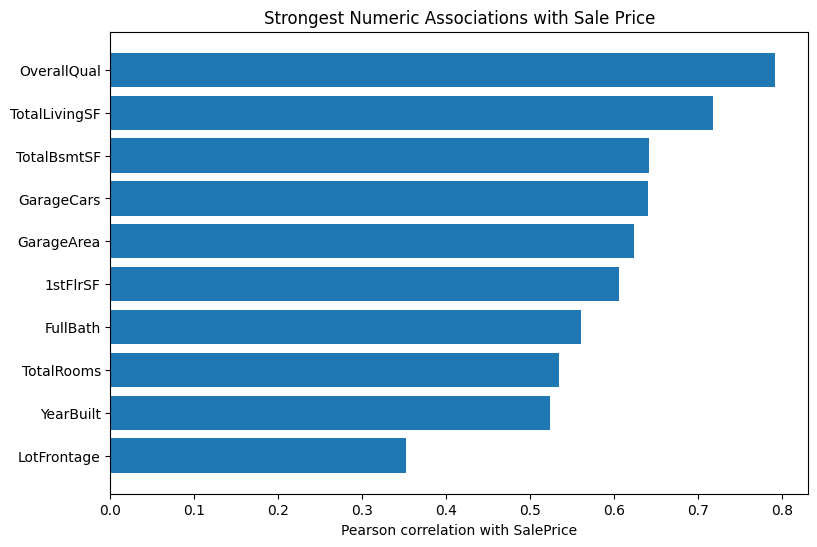

In [7]:
numeric_features = [
    "OverallQual", "TotalLivingSF", "TotalBsmtSF", "GarageCars", "GarageArea",
    "1stFlrSF", "FullBath", "TotalRooms", "YearBuilt", "LotFrontage",
    "2ndFlrSF", "LotArea", "AgeAtSale", "OverallCond", "YrSold"
]

price_corr = (df[numeric_features + ["SalePrice"]]
              .corr(numeric_only=True)["SalePrice"]
              .drop("SalePrice")
              .sort_values(ascending=False))

display(price_corr.to_frame("Correlation with SalePrice").round(3))

plot_corr = price_corr.head(10).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(plot_corr.index, plot_corr.values)
plt.xlabel("Pearson correlation with SalePrice")
plt.title("Strongest Numeric Associations with Sale Price")
plt.show()

,count,mean,median
OverallQual,,,
1,2,"50,150.00","50,150.00"
2,3,"51,770.00","60,000.00"
3,20,"87,474.00","86,250.00"
4,116,"108,421.00","108,000.00"
5,397,"133,523.00","133,000.00"
6,374,"161,603.00","160,000.00"
7,319,"207,716.00","200,141.00"
8,168,"274,736.00","269,750.00"
9,43,"367,513.00","345,000.00"


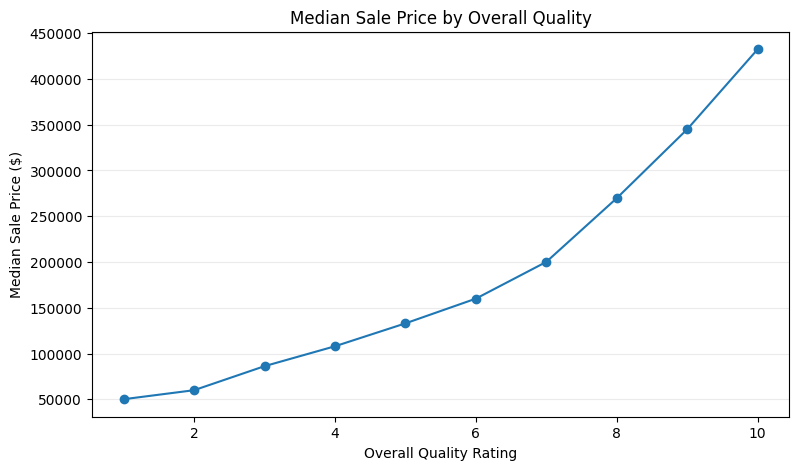

In [8]:
quality_prices = df.groupby("OverallQual")["SalePrice"].agg(["count", "mean", "median"])
display(quality_prices.round(0))

plt.figure(figsize=(9, 5))
plt.plot(quality_prices.index, quality_prices["median"], marker="o")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Median Sale Price ($)")
plt.title("Median Sale Price by Overall Quality")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 7. Supplementary multivariable model

In [9]:
model = smf.ols(
    "np.log(SalePrice) ~ OverallQual + OverallCond + AgeAtSale + "
    "TotalLivingSF + GarageCars + FullBath + TotalRooms + "
    "C(CentralAir) + C(HouseStyle)",
    data=df
).fit(cov_type="HC3")

print(model.summary())
print(f"R-squared: {model.rsquared:.3f}")

key_terms = [
    "OverallQual", "OverallCond", "AgeAtSale", "TotalLivingSF",
    "GarageCars", "C(CentralAir)[T.Y]"
]

rows = []
for term in key_terms:
    beta = model.params[term]
    scale = 100 if term == "TotalLivingSF" else 1
    beta_scaled = beta * scale
    rows.append({
        "Term": term + (" (per 100 sq ft)" if term == "TotalLivingSF" else ""),
        "Approx. % price difference": (np.exp(beta_scaled) - 1) * 100,
        "p-value": model.pvalues[term]
    })

display(pd.DataFrame(rows).round(3))

                            OLS Regression Results                            
Dep. Variable:      np.log(SalePrice)   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                     345.7
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:31:02   Log-Likelihood:                 598.25
No. Observations:                1460   AIC:                            -1164.
Df Residuals:                    1444   BIC:                            -1080.
Df Model:                          15                                         
Covariance Type:                  HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

,Term,Approx. % price difference,p-value
0,OverallQual,10.33,0.00
1,OverallCond,5.47,0.00
2,AgeAtSale,-0.33,0.00
3,TotalLivingSF (per 100 sq ft),3.35,0.00
4,GarageCars,8.76,0.00
5,C(CentralAir)[T.Y],11.05,0.00


### Interpretation of the supplementary model

The regression is descriptive rather than causal. After controlling for the other included characteristics, higher overall quality, better condition, more living area, greater garage capacity, and central air are associated with higher sale prices, while older homes are associated with lower prices. Because the outcome is `log(SalePrice)`, the coefficients can be interpreted approximately as percentage differences. The model explains about 84% of the variation in log sale prices in this fictitious sample. These estimates should support, not replace, individual property inspection and comparable-sale analysis.

## 8. Recommendations

1. **Use the median as the starting benchmark.** The median price ($163,000) is more representative of a typical transaction than the mean because the market has a long high-price tail.
2. **Treat premium homes as a separate segment, not as errors.** Homes above the IQR upper fence should be reviewed separately rather than deleted automatically.
3. **Prioritize quality and usable living space.** Overall quality and total living area have the strongest numeric relationships with sale price.
4. **Consider garage capacity, central air, and age/condition when comparing homes.** These characteristics remain useful indicators in the multivariable analysis.
5. **Do not pay for lot size alone.** Lot area has a much weaker simple relationship with price than quality, living area, basement space, and garage features.
6. **Use property-specific comparables before making an offer.** This dataset contains only 17 attributes and does not include location variation within ABC, taxes, renovation details, financing conditions, or market timing beyond sale year.

## 9. Final verification

In [10]:
assert df.shape == (1460, 19)  # 17 original + 2 derived variables
assert round(df["SalePrice"].mean(), 2) == 180921.20
assert round(df["SalePrice"].std(ddof=1), 2) == 79442.50
assert len(outliers) == 61
assert round(upper_bound, 1) == 340037.5
assert model.nobs == 1460
print("All Case Study 3 checks passed successfully.")

All Case Study 3 checks passed successfully.
